# USD/MXN (DEXMXUS): same analysis as USD/JPY

Cells 1-2 are setup (data + VIX regimes). Everything after mirrors the DEXJPUS-specific cells, with `mx_` prefixed variables so nothing overwrites the JPY results if you paste these into your existing notebook.

In [1]:
import pandas as pd

# Load the datasets
vix_df = pd.read_csv('C:/Users/guosh/OneDrive/Desktop/mfams/VIXCLS_volatility.csv')
fx_df = pd.read_csv('C:/Users/guosh/OneDrive/Desktop/mfams/FXdataDaily_2005_to_2026_Dev_and_underdeve/daily.csv')

# Display the first few rows of each
print("VIX Volatility Data (first 5 rows):")
print(vix_df.head())

print("\nFX Daily Data (first 5 rows):")
print(fx_df.head())

VIX Volatility Data (first 5 rows):
  observation_date  VIXCLS
0       2005-01-03   14.08
1       2005-01-04   13.98
2       2005-01-05   14.09
3       2005-01-06   13.58
4       2005-01-07   13.49

FX Daily Data (first 5 rows):
  observation_date  DEXBZUS  DEXCAUS  DEXCHUS  DEXDNUS  DEXHKUS  DEXINUS  \
0       2005-01-03   2.6695   1.2108   8.2765   5.5161   7.7775    43.35   
1       2005-01-04   2.7020   1.2248   8.2765   5.5927   7.7851    43.47   
2       2005-01-05   2.6970   1.2236   8.2765   5.5959   7.7881    43.60   
3       2005-01-06   2.7190   1.2371   8.2765   5.6417   7.7935    43.75   
4       2005-01-07   2.7095   1.2333   8.2765   5.6951   7.7920    43.63   

   DEXJPUS  DEXKOUS  DEXMAUS  ...  DEXUSEU  DEXUSNZ  DEXUSUK  DEXVZUS  \
0   102.83   1038.0      3.8  ...   1.3476   0.7148   1.9058   1.9152   
1   104.27   1038.0      3.8  ...   1.3295   0.7069   1.8834   1.9152   
2   103.95   1046.3      3.8  ...   1.3292   0.7030   1.8875   1.9152   
3   104.87   1058.0   

In [2]:
# Convert VIXCLS column to numeric, handling missing or non-numeric values (coercing them to NaN)
vix_df['VIXCLS'] = pd.to_numeric(vix_df['VIXCLS'], errors='coerce')

# Filter the rows based on the threshold of 30
High_volatility = vix_df[vix_df['VIXCLS'] > 30].copy()
Medium_volatility = vix_df[(vix_df['VIXCLS'] <= 30) & (vix_df['VIXCLS'] > 15)].copy()
Low_volatility = vix_df[vix_df['VIXCLS'] <= 15].copy()

# Display the sizes and preview of each dataset
print(f"High Volatility shape: {High_volatility.shape}")
print(f"Medium Volatility shape: {Medium_volatility.shape}")
print(f"Low Volatility shape: {Low_volatility.shape}")

print("\nHigh Volatility Preview:")
display(High_volatility.head())

print("\nMedium Volatility Preview:")
display(Medium_volatility.head())

print("\nLow Volatility Preview:")
display(Low_volatility.head())

High Volatility shape: (450, 2)
Medium Volatility shape: (3045, 2)
Low Volatility shape: (2019, 2)

High Volatility Preview:


,observation_date,VIXCLS
682,2007-08-15,30.67
683,2007-08-16,30.83
745,2007-11-12,31.09
796,2008-01-22,31.01
834,2008-03-14,31.16



Medium Volatility Preview:


,observation_date,VIXCLS
74,2005-04-15,17.74
75,2005-04-18,16.56
77,2005-04-20,16.92
79,2005-04-22,15.38
83,2005-04-28,16.86



Low Volatility Preview:


,observation_date,VIXCLS
0,2005-01-03,14.08
1,2005-01-04,13.98
2,2005-01-05,14.09
3,2005-01-06,13.58
4,2005-01-07,13.49


Refitted through forecast 500 of 4,954 (2008-12-22).
Refitted through forecast 1,000 of 4,954 (2010-12-17).
Refitted through forecast 1,500 of 4,954 (2012-12-14).
Refitted through forecast 2,000 of 4,954 (2014-12-12).
Refitted through forecast 2,500 of 4,954 (2016-12-12).
Refitted through forecast 3,000 of 4,954 (2018-12-12).
Refitted through forecast 3,500 of 4,954 (2020-12-15).
Refitted through forecast 4,000 of 4,954 (2022-12-16).
Refitted through forecast 4,500 of 4,954 (2024-12-17).


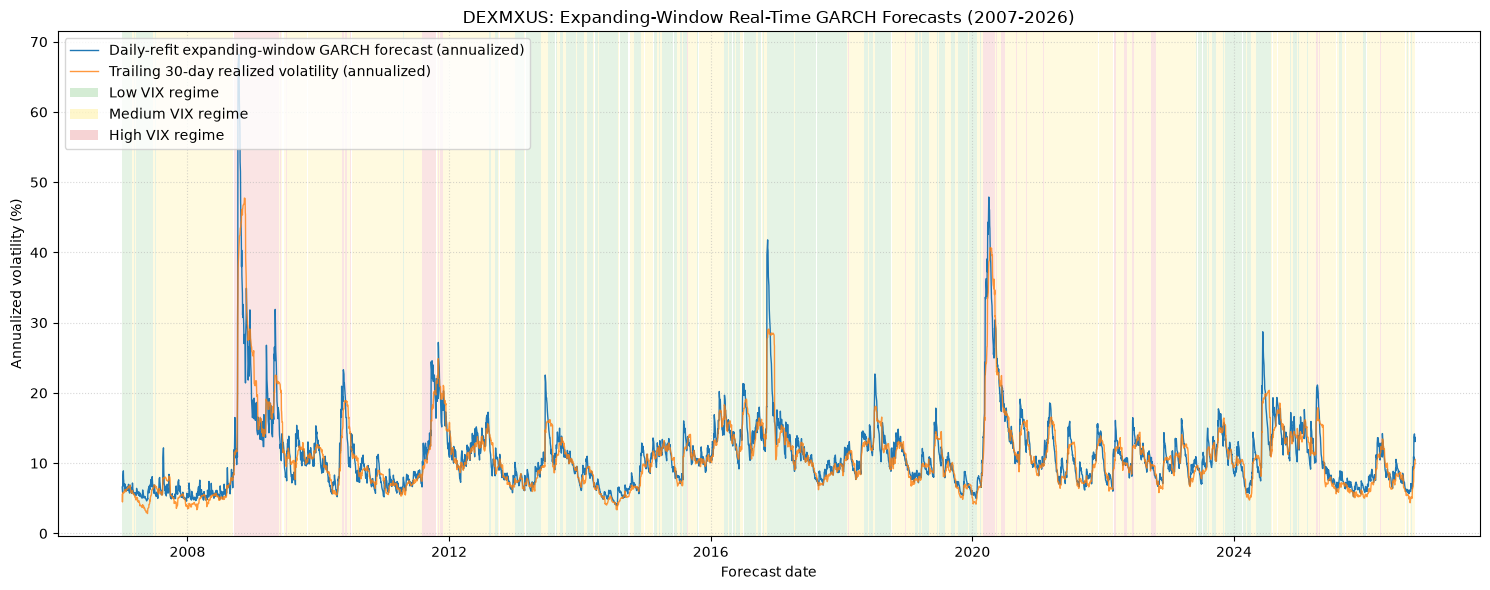

Initial fit period: 2005-01-04 to 2006-12-29
Forecast period: 2007-01-02 to 2026-10-09
Daily refits/forecasts: 4,954


In [3]:
# Expanding-window real-time GARCH(1,1) forecasts for DEXMXUS.
# Estimate on 2005-2006, then refit each day using only returns available
# before that day's forecast; add the observed return after forecasting.

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.patches import Patch
from arch import arch_model

mx_expanding_fx = fx_df[['observation_date', 'DEXMXUS']].copy()
mx_expanding_fx['observation_date'] = pd.to_datetime(mx_expanding_fx['observation_date'], errors='coerce')
mx_expanding_fx['DEXMXUS'] = pd.to_numeric(mx_expanding_fx['DEXMXUS'], errors='coerce')
mx_expanding_fx = mx_expanding_fx.dropna().set_index('observation_date').sort_index()
mx_expanding_returns = mx_expanding_fx['DEXMXUS'].pct_change(fill_method=None).dropna() * 100

mx_initial_returns = mx_expanding_returns.loc['2005-01-01':'2006-12-31']
mx_forecast_returns = mx_expanding_returns.loc['2007-01-01':'2026-12-31']
if mx_initial_returns.empty or mx_forecast_returns.empty:
    raise ValueError('DEXMXUS data must include returns in both 2005-2006 and 2007-2026.')

mx_expanding_history = mx_initial_returns.copy()
mx_expanding_forecast_variances = pd.Series(
    index=mx_forecast_returns.index,
    dtype=float,
    name='One-day-ahead GARCH forecast variance'
)

for step, (forecast_date, observed_return) in enumerate(mx_forecast_returns.items(), start=1):
    mx_expanding_model = arch_model(
        mx_expanding_history,
        mean='Constant',
        vol='Garch',
        p=1,
        q=1,
        dist='normal'
    )
    mx_expanding_fit = mx_expanding_model.fit(disp='off')
    forecast_variance = mx_expanding_fit.forecast(horizon=1, reindex=False).variance.iloc[-1, 0]
    mx_expanding_forecast_variances.loc[forecast_date] = forecast_variance

    # Include today's observed return only after its forecast has been recorded.
    mx_expanding_history.loc[forecast_date] = observed_return

    if step % 500 == 0:
        print(f'Refitted through forecast {step:,} of {len(mx_forecast_returns):,} ({forecast_date.date()}).')

mx_expanding_forecast_volatility = np.sqrt(mx_expanding_forecast_variances) * np.sqrt(252)
mx_expanding_realized_volatility = (
    mx_expanding_returns.rolling(window=30, min_periods=30).std() * np.sqrt(252)
).reindex(mx_forecast_returns.index)

mx_expanding_vix = vix_df[['observation_date', 'VIXCLS']].copy()
mx_expanding_vix['observation_date'] = pd.to_datetime(mx_expanding_vix['observation_date'], errors='coerce')
mx_expanding_vix['VIXCLS'] = pd.to_numeric(mx_expanding_vix['VIXCLS'], errors='coerce')
mx_expanding_vix = mx_expanding_vix.dropna().set_index('observation_date')['VIXCLS'].sort_index()
mx_expanding_vix = mx_expanding_vix.reindex(mx_forecast_returns.index, method='ffill')
if mx_expanding_vix.notna().sum() == 0:
    raise ValueError('No VIX observations overlap the GARCH forecast period.')

mx_expanding_vix_regime = pd.Series(
    np.select([mx_expanding_vix > 30, mx_expanding_vix > 15], ['High', 'Medium'], default='Low'),
    index=mx_expanding_vix.index,
).where(mx_expanding_vix.notna())
mx_expanding_regime_colors = {'Low': 'tab:green', 'Medium': 'gold', 'High': 'tab:red'}
mx_expanding_regime_groups = mx_expanding_vix_regime.ne(mx_expanding_vix_regime.shift()).cumsum()


fig, ax = plt.subplots(figsize=(15, 6))
for _, regime_dates in mx_expanding_vix_regime.groupby(mx_expanding_regime_groups):
    regime = regime_dates.iloc[0]
    if pd.notna(regime):
        ax.axvspan(
            regime_dates.index[0],
            regime_dates.index[-1] + pd.Timedelta(days=1),
            color=mx_expanding_regime_colors[regime],
            alpha=0.12,
            linewidth=0,
            zorder=0,
        )
ax.plot(
    mx_expanding_forecast_volatility.index,
    mx_expanding_forecast_volatility,
    color='tab:blue',
    linewidth=1,
    label='Daily-refit expanding-window GARCH forecast (annualized)'
)
ax.plot(
    mx_expanding_realized_volatility.index,
    mx_expanding_realized_volatility,
    color='tab:orange',
    linewidth=1,
    alpha=0.8,
    label='Trailing 30-day realized volatility (annualized)'
)
ax.set_title('DEXMXUS: Expanding-Window Real-Time GARCH Forecasts (2007-2026)')
ax.set_xlabel('Forecast date')
ax.set_ylabel('Annualized volatility (%)')
ax.grid(True, linestyle=':', alpha=0.5)
line_handles, line_labels = ax.get_legend_handles_labels()
regime_handles = [
    Patch(facecolor=mx_expanding_regime_colors[name], alpha=0.2, label=f'{name} VIX regime')
    for name in ['Low', 'Medium', 'High']
]
ax.legend(handles=line_handles + regime_handles,
          labels=line_labels + [handle.get_label() for handle in regime_handles])
fig.tight_layout()
plt.show()

print(f'Initial fit period: {mx_initial_returns.index.min().date()} to {mx_initial_returns.index.max().date()}')
print(f'Forecast period: {mx_forecast_returns.index.min().date()} to {mx_forecast_returns.index.max().date()}')
print(f'Daily refits/forecasts: {mx_expanding_forecast_volatility.notna().sum():,}')

In [4]:
# 1. Load the newly created daily S&P 500 dataset and daily currency dataset
sp500_daily = pd.read_csv('C:/Users/guosh/OneDrive/Desktop/mfams/sp500_price_2005_to_now.csv')
mx_daily_df = pd.read_csv('C:/Users/guosh/OneDrive/Desktop/mfams/FXdataDaily_2005_to_2026_Dev_and_underdeve/daily.csv')


# Convert Date columns to datetime format
sp500_daily['Date'] = pd.to_datetime(sp500_daily['Date'])
mx_daily_df['Date'] = pd.to_datetime(mx_daily_df['observation_date'])

# Set Date as index
sp500_daily.set_index('Date', inplace=True)
mx_daily_df.set_index('Date', inplace=True)

# Clean and convert the USD/MXN column ('DEXMXUS') to numeric
mx_daily_df['DEXMXUS'] = pd.to_numeric(mx_daily_df['DEXMXUS'], errors='coerce')
mx_daily_df.dropna(subset=['DEXMXUS'], inplace=True)

# 2. Create columns for percentage returns each day
sp500_daily['sp500_pct_return'] = sp500_daily['Value'].pct_change()
mx_daily_df['mxn_pct_return'] = mx_daily_df['DEXMXUS'].pct_change()

# 3. Merge datasets using Date as index
mx_merged_df = pd.merge(
    sp500_daily[['Value', 'sp500_pct_return']],
    mx_daily_df[['DEXMXUS', 'mxn_pct_return']],
    left_index=True,
    right_index=True,
    how='inner'
).sort_index()

# Rename columns for clarity
mx_merged_df.rename(columns={'Value': 'sp500_price', 'DEXMXUS': 'mxn_price'}, inplace=True)

# Drop rows with NaN values in returns
mx_merged_df.dropna(subset=['sp500_pct_return', 'mxn_pct_return'], inplace=True)

display(mx_merged_df.head())

,sp500_price,sp500_pct_return,mxn_price,mxn_pct_return
Date,,,,
2005-01-04,1188.050049,-0.011671,11.3191,0.009282
2005-01-05,1183.739990,-0.003628,11.3340,0.001316
2005-01-06,1187.890015,0.003506,11.4110,0.006794
2005-01-07,1186.189941,-0.001431,11.3600,-0.004469
2005-01-10,1190.250000,0.003423,11.2550,-0.009243


Beta measures the sensitivity of USD/MXN returns to S&P 500 returns. Formula:  β = Covariance(R_mxn, R_sp500) / Variance(R_sp500). We compute this over a rolling window of 252 trading days.

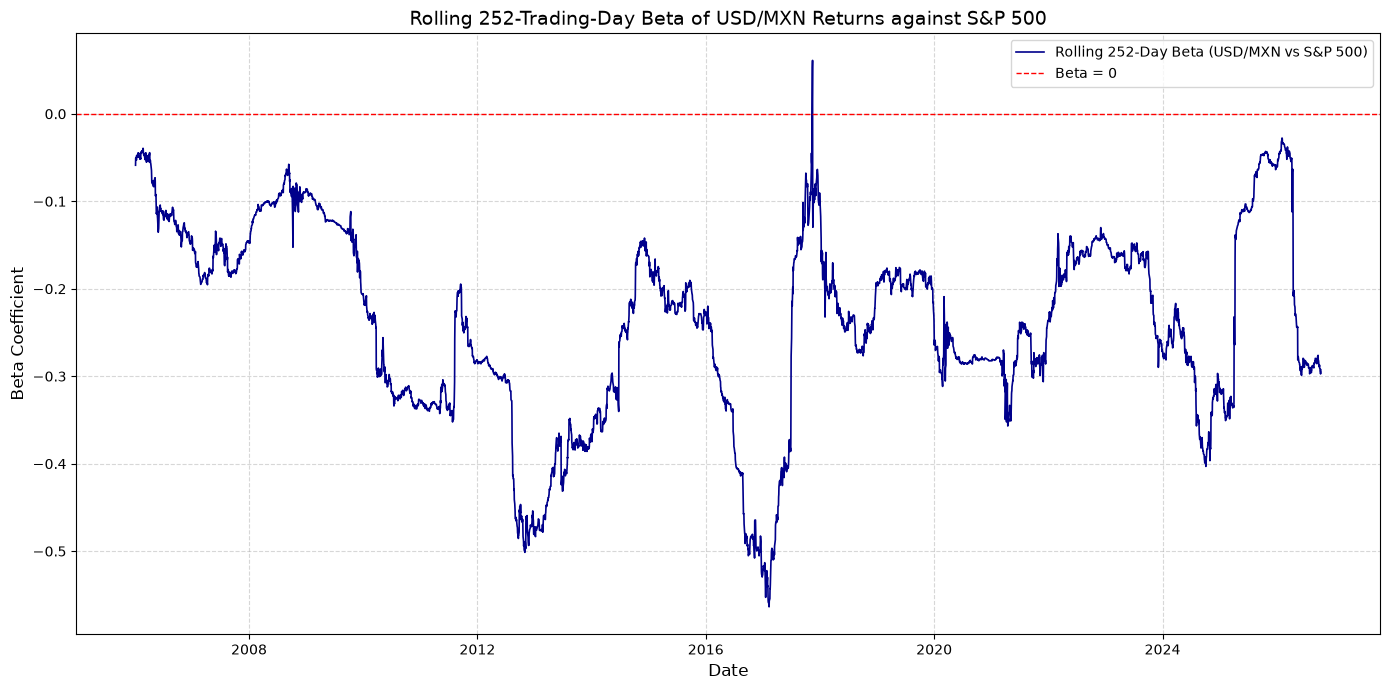

In [5]:
import matplotlib.pyplot as plt

# 4. Calculate statistical metrics (Beta) over a moving window of 252 trading days
mx_rolling_window = 252

# Rolling covariance of MXN returns vs S&P 500 returns
mx_rolling_covariance = mx_merged_df['mxn_pct_return'].rolling(window=mx_rolling_window).cov(mx_merged_df['sp500_pct_return'])

# Rolling variance of S&P 500 returns
mx_rolling_variance = mx_merged_df['sp500_pct_return'].rolling(window=mx_rolling_window).var()

# Compute Beta
mx_merged_df['mx_rolling_beta'] = mx_rolling_covariance / mx_rolling_variance

# 5. Plot the rolling Beta over the timeline
plt.figure(figsize=(14, 7))
plt.plot(mx_merged_df.index, mx_merged_df['mx_rolling_beta'], label='Rolling 252-Day Beta (USD/MXN vs S&P 500)', color='darkblue', linewidth=1.2)
plt.axhline(0, color='red', linestyle='--', linewidth=1, label='Beta = 0')
plt.title('Rolling 252-Trading-Day Beta of USD/MXN Returns against S&P 500', fontsize=14)
plt.xlabel('Date', fontsize=12)
plt.ylabel('Beta Coefficient', fontsize=12)
plt.grid(True, linestyle='--', alpha=0.5)
plt.legend(loc='best')
plt.tight_layout()
plt.show()

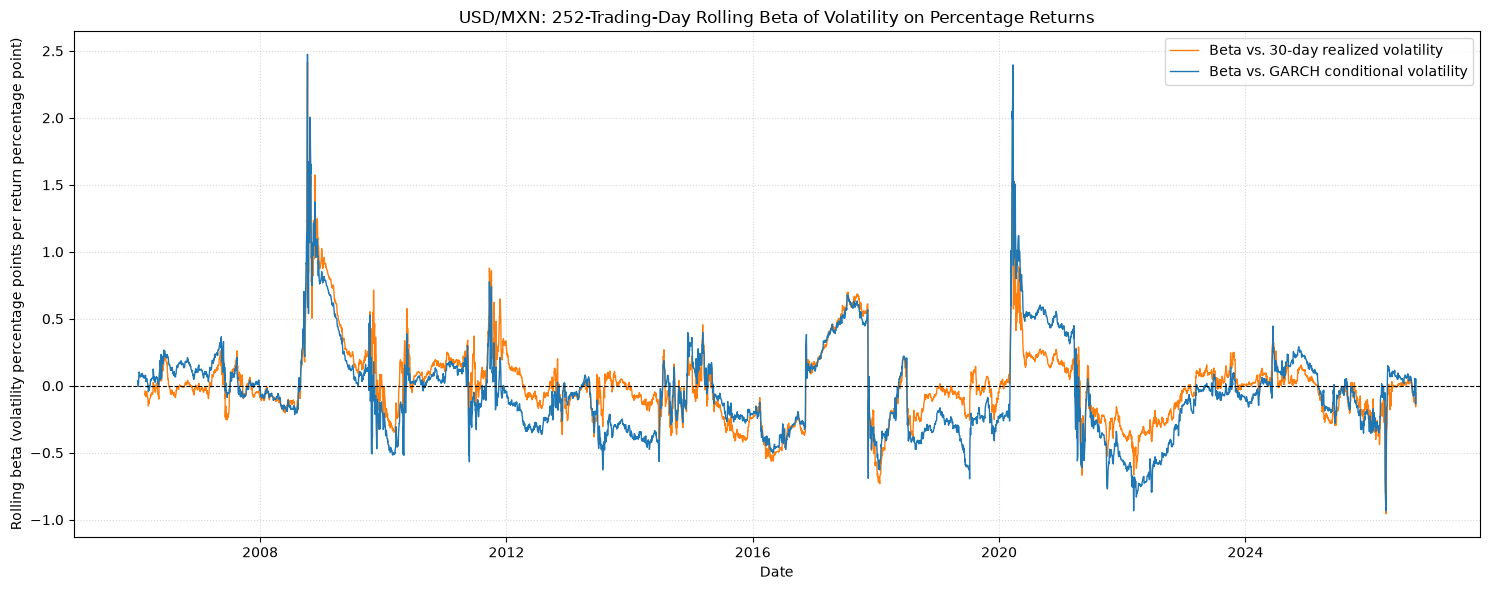

Rolling window: 252 trading days
Beta date range: 2006-01-04 to 2026-10-09


,Rolling beta vs. 30-day realized volatility,Rolling beta vs. GARCH volatility
observation_date,,
2026-10-05,-0.129877,-0.072750
2026-10-06,-0.155947,-0.136391
2026-10-07,-0.156986,-0.128919
2026-10-08,-0.116400,-0.052945
2026-10-09,-0.051226,0.048812


In [6]:
# Rolling 252-trading-day beta: USD/MXN percentage returns vs. volatility.
# Beta is the slope from volatility_t = alpha + beta * return_t + error_t.
from arch import arch_model
from IPython.display import display

mx_rolling_fx = fx_df[['observation_date', 'DEXMXUS']].copy()
mx_rolling_fx['observation_date'] = pd.to_datetime(mx_rolling_fx['observation_date'], errors='coerce')
mx_rolling_fx['DEXMXUS'] = pd.to_numeric(mx_rolling_fx['DEXMXUS'], errors='coerce')
mx_rolling_fx = mx_rolling_fx.dropna().set_index('observation_date').sort_index()

# Daily USD/MXN percentage returns, expressed in percentage points.
mx_rolling_returns_pct = mx_rolling_fx['DEXMXUS'].pct_change(fill_method=None).dropna() * 100

# Compare returns with two volatility measures, both annualized in percent.
mx_rolling_realized_vol = (
    mx_rolling_returns_pct.rolling(window=30, min_periods=30).std() * np.sqrt(252)
)
mx_rolling_garch_fit = arch_model(
    mx_rolling_returns_pct, mean='Constant', vol='Garch', p=1, q=1, dist='normal'
).fit(disp='off')
mx_rolling_garch_vol = mx_rolling_garch_fit.conditional_volatility * np.sqrt(252)

# Rolling beta = rolling covariance(return, volatility) / rolling variance(return).
mx_rolling_beta_window = 252
mx_rolling_return_variance = mx_rolling_returns_pct.rolling(
    window=mx_rolling_beta_window, min_periods=mx_rolling_beta_window
).var()
mx_rolling_beta_realized = (
    mx_rolling_returns_pct.rolling(window=mx_rolling_beta_window, min_periods=mx_rolling_beta_window)
    .cov(mx_rolling_realized_vol)
    .div(mx_rolling_return_variance)
)
mx_rolling_beta_garch = (
    mx_rolling_returns_pct.rolling(window=mx_rolling_beta_window, min_periods=mx_rolling_beta_window)
    .cov(mx_rolling_garch_vol)
    .div(mx_rolling_return_variance)
)

mx_rolling_beta_results = pd.DataFrame({
    'Rolling beta vs. 30-day realized volatility': mx_rolling_beta_realized,
    'Rolling beta vs. GARCH volatility': mx_rolling_beta_garch,
}).dropna(how='all')
if mx_rolling_beta_results.empty:
    raise ValueError('Not enough aligned USD/MXN observations to calculate a 252-day rolling beta.')

fig, ax = plt.subplots(figsize=(15, 6))
ax.plot(
    mx_rolling_beta_results.index,
    mx_rolling_beta_results['Rolling beta vs. 30-day realized volatility'],
    color='tab:orange', linewidth=1,
    label='Beta vs. 30-day realized volatility'
)
ax.plot(
    mx_rolling_beta_results.index,
    mx_rolling_beta_results['Rolling beta vs. GARCH volatility'],
    color='tab:blue', linewidth=1,
    label='Beta vs. GARCH conditional volatility'
)
ax.axhline(0, color='black', linewidth=0.8, linestyle='--')
ax.set_title('USD/MXN: 252-Trading-Day Rolling Beta of Volatility on Percentage Returns')
ax.set_xlabel('Date')
ax.set_ylabel('Rolling beta (volatility percentage points per return percentage point)')
ax.grid(True, linestyle=':', alpha=0.5)
ax.legend()
fig.tight_layout()
plt.show()

print(f'Rolling window: {mx_rolling_beta_window} trading days')
print(f'Beta date range: {mx_rolling_beta_results.index.min().date()} to {mx_rolling_beta_results.index.max().date()}')
display(mx_rolling_beta_results.tail())